<a href="https://colab.research.google.com/github/trduong01/MachineLearning-BTVN/blob/main/MachineLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

BÀI 1: TĂNG ĐỘ NHIỄU VÀ ĐÁNH GIÁ SỰ ẢNH HƯỞNG ĐẾN MÔ HÌNH HỒI QUY
Nhiễu (Std =  100) -> R2 Score: 0.9954 | MSE: 6674.52
Nhiễu (Std =  500) -> R2 Score: 0.8429 | MSE: 220575.69
Nhiễu (Std = 1500) -> R2 Score: 0.3850 | MSE: 2115893.88
Nhiễu (Std = 3000) -> R2 Score: 0.0725 | MSE: 12260790.97


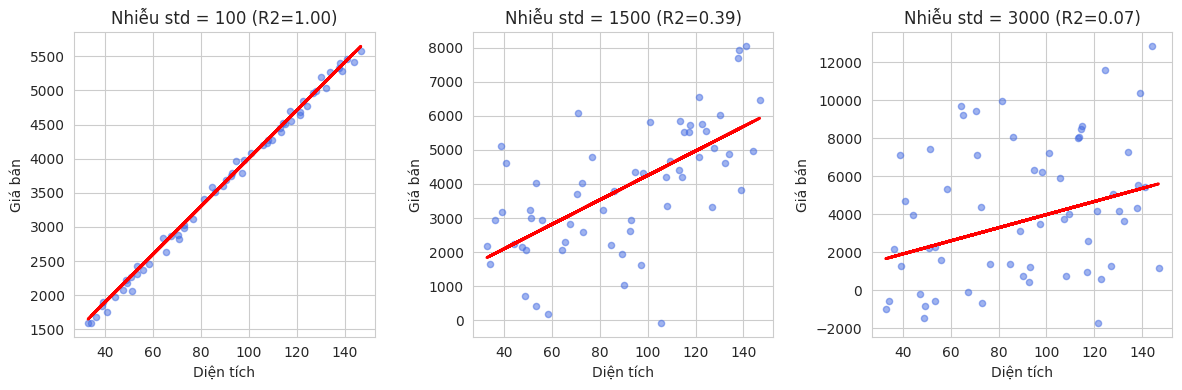


BÀI 2: THAY ĐỔI NGƯỠNG XÁC SUẤT (THRESHOLD) TRONG HỒI QUY LOGISTIC

--- NGƯỠNG (THRESHOLD) = 0.3 ---
Độ chính xác (Accuracy): 90.00%
Ma trận nhầm lẫn:
[[32  6]
 [ 4 58]]

--- NGƯỠNG (THRESHOLD) = 0.5 ---
Độ chính xác (Accuracy): 90.00%
Ma trận nhầm lẫn:
[[34  4]
 [ 6 56]]

--- NGƯỠNG (THRESHOLD) = 0.7 ---
Độ chính xác (Accuracy): 93.00%
Ma trận nhầm lẫn:
[[38  0]
 [ 7 55]]

--- NGƯỠNG (THRESHOLD) = 0.85 ---
Độ chính xác (Accuracy): 86.00%
Ma trận nhầm lẫn:
[[38  0]
 [14 48]]

BÀI 3: HỒI QUY TUYẾN TÍNH VỚI BỘ DỮ LIỆU NHÀ (BOSTON HOUSING)
Kích thước bộ dữ liệu Boston: 506 dòng, 14 cột
      crim    zn  indus  chas    nox     rm   age     dis  rad  tax  ptratio  \
0  0.00632  18.0   2.31     0  0.538  6.575  65.2  4.0900    1  296     15.3   
1  0.02731   0.0   7.07     0  0.469  6.421  78.9  4.9671    2  242     17.8   
2  0.02729   0.0   7.07     0  0.469  7.185  61.1  4.9671    2  242     17.8   

        b  lstat  medv  
0  396.90   4.98  24.0  
1  396.90   9.14  21.6  
2  392.83   4

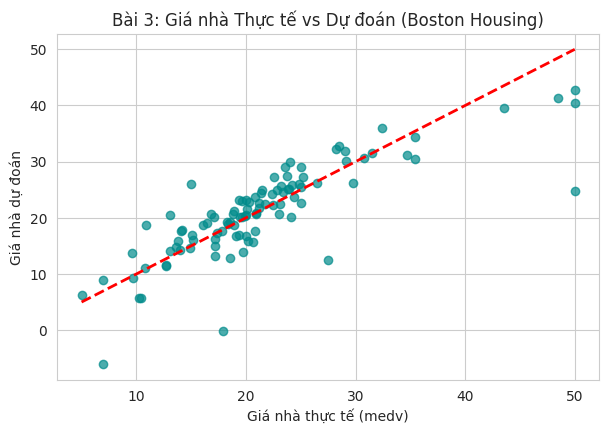

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix, classification_report

plt.rcParams['figure.dpi'] = 100
sns.set_style("whitegrid")

print("=" * 65)
print("BÀI 1: TĂNG ĐỘ NHIỄU VÀ ĐÁNH GIÁ SỰ ẢNH HƯỞNG ĐẾN MÔ HÌNH HỒI QUY")
print("=" * 65)

np.random.seed(42)
n_samples = 300
dien_tich = np.random.uniform(30, 150, n_samples)

# Thử nghiệm với các mức độ nhiễu (Noise standard deviation) khác nhau
noise_levels = [100, 500, 1500, 3000]
results = []

plt.figure(figsize=(12, 4))
for i, noise_std in enumerate(noise_levels):
    # Tạo giá bán với độ nhiễu tương ứng
    noise = np.random.normal(0, noise_std, n_samples)
    gia_ban = 500 + 35 * dien_tich + noise

    X = dien_tich.reshape(-1, 1)
    X_train, X_test, y_train, y_test = train_test_split(X, gia_ban, test_size=0.2, random_state=42)

    model = LinearRegression()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    results.append({'Noise (Std)': noise_std, 'R2 Score': r2, 'MSE': mse})

    print(f"Nhiễu (Std = {noise_std:4d}) -> R2 Score: {r2:.4f} | MSE: {mse:.2f}")

    # Vẽ biểu đồ trực quan hóa độ phân tán
    if i in [0, 2, 3]: # Vẽ 3 mức nhiễu minh họa
        plt.subplot(1, 3, [0, 2, 3].index(i) + 1)
        plt.scatter(X_test, y_test, alpha=0.5, color='royalblue', s=20)
        plt.plot(X_test, model.predict(X_test), color='red', lw=2)
        plt.title(f'Nhiễu std = {noise_std} (R2={r2:.2f})')
        plt.xlabel('Diện tích')
        plt.ylabel('Giá bán')

plt.tight_layout()
plt.show()


print("\n" + "=" * 65)
print("BÀI 2: THAY ĐỔI NGƯỠNG XÁC SUẤT (THRESHOLD) TRONG HỒI QUY LOGISTIC")
print("=" * 65)

# Tạo lại dữ liệu BMI giả lập
n_patients = 400
bmi = np.random.uniform(16, 40, n_patients)
z = 0.55 * (bmi - 25.5)
prob_disease = 1 / (1 + np.exp(-z))
mac_benh = np.random.binomial(1, prob_disease)

X_bmi = bmi.reshape(-1, 1)
y_bmi = mac_benh
X_b_train, X_b_test, y_b_train, y_b_test = train_test_split(X_bmi, y_bmi, test_size=0.25, random_state=42)

log_model = LogisticRegression()
log_model.fit(X_b_train, y_b_train)

# Lấy xác suất dự đoán lớp 1 (mắc bệnh)
y_prob_test = log_model.predict_proba(X_b_test)[:, 1]

# Thử nghiệm các ngưỡng phân loại khác nhau
thresholds = [0.3, 0.5, 0.7, 0.85]

for th in thresholds:
    # Chuyển đổi xác suất thành nhãn dựa trên ngưỡng tùy chỉnh
    y_pred_th = (y_prob_test >= th).astype(int)
    acc = accuracy_score(y_b_test, y_pred_th)
    cm = confusion_matrix(y_b_test, y_pred_th)

    print(f"\n--- NGƯỠNG (THRESHOLD) = {th} ---")
    print(f"Độ chính xác (Accuracy): {acc * 100:.2f}%")
    print("Ma trận nhầm lẫn:")
    print(cm)


print("\n" + "=" * 65)
print("BÀI 3: HỒI QUY TUYẾN TÍNH VỚI BỘ DỮ LIỆU NHÀ (BOSTON HOUSING)")
print("=" * 65)

# Tải bộ dữ liệu Boston Housing từ nguồn trực tuyến uy tín (do sklearn đã loại bỏ load_boston ở các phiên bản mới)
url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
df_boston = pd.read_csv(url)

print(f"Kích thước bộ dữ liệu Boston: {df_boston.shape[0]} dòng, {df_boston.shape[1]} cột")
print(df_boston.head(3))

# Phân chia đặc trưng (X) và biến mục tiêu (y - cột 'medv' là giá nhà trung bình)
X_boston = df_boston.drop(columns=['medv'])
y_boston = df_boston['medv']

# Chia tập huấn luyện và tập kiểm tra (80% train, 20% test)
X_bo_train, X_bo_test, y_bo_train, y_bo_test = train_test_split(
    X_boston, y_boston, test_size=0.2, random_state=42
)

# Huấn luyện mô hình Linear Regression
boston_model = LinearRegression()
boston_model.fit(X_bo_train, y_bo_train)

# Dự đoán trên tập kiểm tra
y_bo_pred = boston_model.predict(X_bo_test)

# Tính toán các chỉ số đánh giá
mse_boston = mean_squared_error(y_bo_test, y_bo_pred)
r2_boston = r2_score(y_bo_test, y_bo_pred)

print(f"\n--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH TRÊN TẬP TEST ---")
print(f"Mean Squared Error (MSE): {mse_boston:.4f}")
print(f"R² Score: {r2_boston:.4f}")

# Trực quan hóa Giá thực tế vs Giá dự đoán
plt.figure(figsize=(7, 4.5))
plt.scatter(y_bo_test, y_bo_pred, alpha=0.7, color='darkcyan')
plt.plot([y_bo_test.min(), y_bo_test.max()], [y_bo_test.min(), y_bo_test.max()], 'r--', lw=2)
plt.title('Bài 3: Giá nhà Thực tế vs Dự đoán (Boston Housing)')
plt.xlabel('Giá nhà thực tế (medv)')
plt.ylabel('Giá nhà dự đoán')
plt.show()